In [ ]:
Investigate transaction data for patterns and anomalies by visualizing feature distributions and applying PCA to reduce dimensionality. Use these visualizations to identify clusters and outliers, then build an anomaly detection model to flag fraudulent transactions, visualizing detected anomalies in 2D or 3D PCA space. [Credit Card Fraud Dataset]

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
import seaborn as sns

In [2]:
# 1. Load and inspect dataset
# ---------------------------
transactions = pd.read_csv("creditcard_2023.csv")


print(transactions.head())
print(transactions.info())

# Drop non-numeric features (IDs, categorical if not encoded yet)
df_num = transactions.select_dtypes(include=[np.number])


   id        V1        V2        V3        V4        V5        V6        V7  \
0   0 -0.260648 -0.469648  2.496266 -0.083724  0.129681  0.732898  0.519014   
1   1  0.985100 -0.356045  0.558056 -0.429654  0.277140  0.428605  0.406466   
2   2 -0.260272 -0.949385  1.728538 -0.457986  0.074062  1.419481  0.743511   
3   3 -0.152152 -0.508959  1.746840 -1.090178  0.249486  1.143312  0.518269   
4   4 -0.206820 -0.165280  1.527053 -0.448293  0.106125  0.530549  0.658849   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0 -0.130006  0.727159  ... -0.110552  0.217606 -0.134794  0.165959  0.126280   
1 -0.133118  0.347452  ... -0.194936 -0.605761  0.079469 -0.577395  0.190090   
2 -0.095576 -0.261297  ... -0.005020  0.702906  0.945045 -1.154666 -0.605564   
3 -0.065130 -0.205698  ... -0.146927 -0.038212 -0.214048 -1.893131  1.003963   
4 -0.212660  1.049921  ... -0.106984  0.729727 -0.161666  0.312561 -0.414116   

        V26       V27       V28    Amount  C

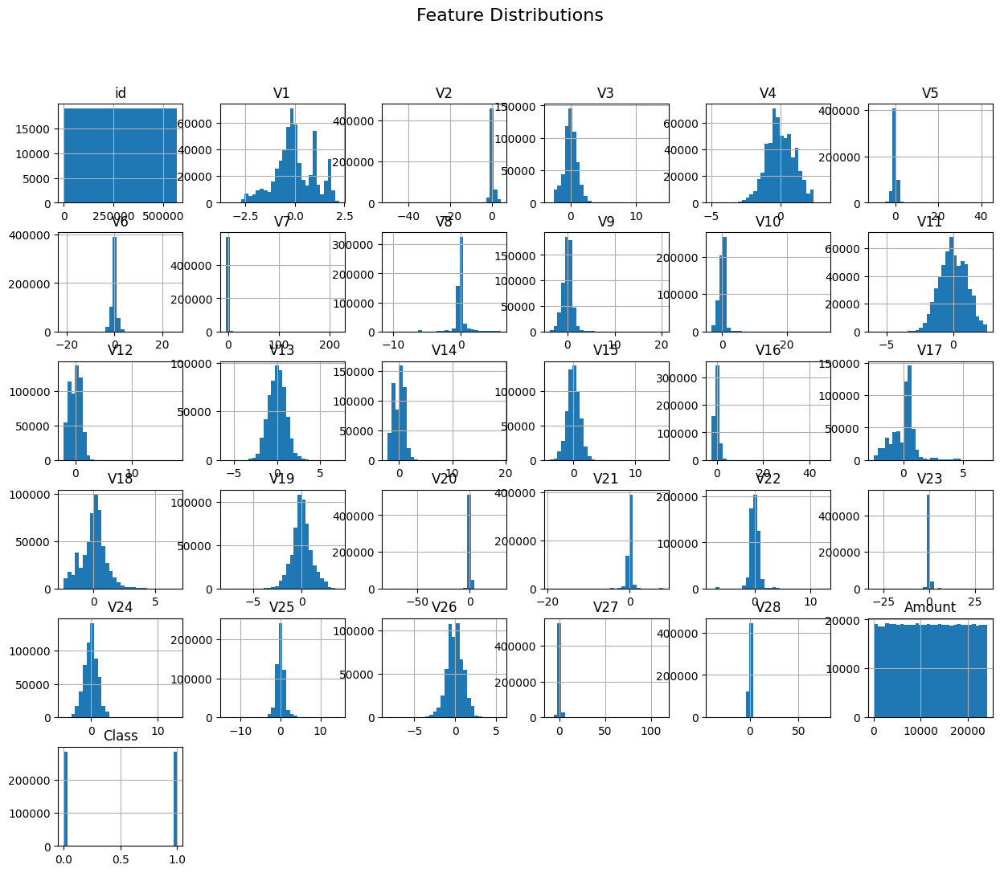

In [3]:
# 2. Feature distribution visualization
# ---------------------------
df_num.hist(bins=30, figsize=(15, 12))
plt.suptitle("Feature Distributions", fontsize=16)
plt.show()

# Pairplot for relationships
sns.pairplot(df_num.sample(min(500, len(df_num))))  # sample for speed
plt.show()


Explained variance ratio: [0.34981872 0.09184952 0.06759947]


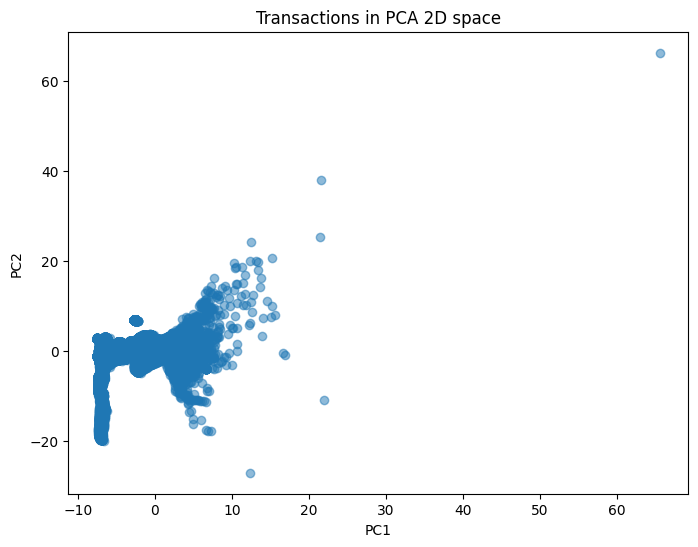

In [4]:
# 3. Standardization & PCA
# ---------------------------
# Drop rows with missing values
df_num = df_num.dropna()

scaler = StandardScaler()
scaled = scaler.fit_transform(df_num)

pca = PCA(n_components=3)  # keep 3D for visualization
pca_result = pca.fit_transform(scaled)

print("Explained variance ratio:", pca.explained_variance_ratio_)

# 2D PCA scatter
plt.figure(figsize=(8,6))
plt.scatter(pca_result[:,0], pca_result[:,1], alpha=0.5)
plt.title("Transactions in PCA 2D space")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

In [ ]:
# 4. Anomaly detection (Isolation Forest)
# ---------------------------
iso = IsolationForest(contamination=0.02, random_state=42)
# Fit and predict on the data without missing values
labels = iso.fit_predict(df_num)

# Create a new column "anomaly" in the original transactions DataFrame,
# initialized with a default value (e.g., 0).
transactions["anomaly"] = 0

# Align the anomaly labels with the original transactions DataFrame
# based on the index of df_num.
transactions.loc[df_num.index, "anomaly"] = labels

In [ ]:
# 5. Visualize anomalies in PCA space
# ---------------------------
plt.figure(figsize=(8,6))
plt.scatter(pca_result[:,0], pca_result[:,1], c=(labels==-1), cmap="coolwarm", alpha=0.6)
plt.title("Anomalies in PCA 2D space")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

# 3D visualization
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(pca_result[:,0], pca_result[:,1], pca_result[:,2],
           c=(labels==-1), cmap="coolwarm", alpha=0.6)
ax.set_title("Anomalies in PCA 3D space")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
plt.show()